# Numerical roots and integration

**Two questions.** Where does a curve cross zero? How can we approximate the area under a curve?

We will start with $g(x)=x^2-2$, then use bisection to solve $\cos x=x$. The integration example returns to $g(x)=x^2-2$. Python implements bisection, NumPy handles the samples, Matplotlib draws the graphs, and SymPy supplies exact reference values. Run the cells in order. If needed, run **%pip install numpy matplotlib sympy** in a new cell.

In [1]:
from math import cos

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

g = lambda x: x**2 - 2
plt.rcParams.update({"figure.dpi": 120, "grid.alpha": 0.25})

## 1. A root and a sign change

A **root** is an input where a function equals zero. If a continuous function has endpoint values with opposite signs, the **Intermediate Value Theorem** guarantees at least one root between them. An interval with this property is called a **sign-changing bracket**. A zero at either endpoint can be returned immediately.

For $g(x)=x^2-2$, we have $g(1)=-1$ and $g(2)=2$. The curve starts below zero and ends above it, so $[1,2]$ brackets the positive root.

**Predict.** The first midpoint is $1.5$. Which half still has opposite signs?

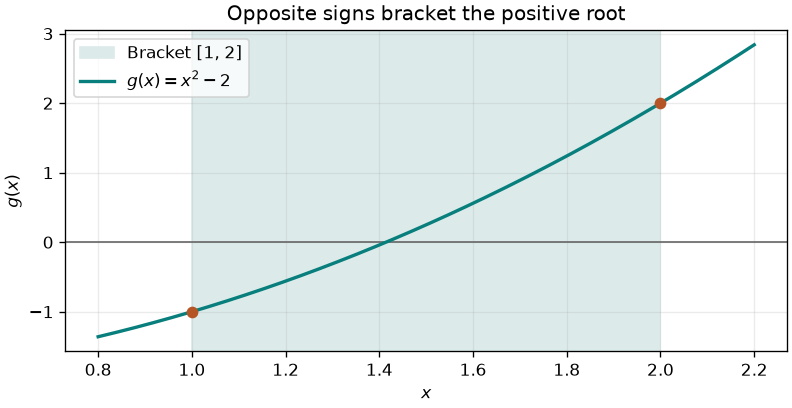

In [2]:
plot_x = np.linspace(0.8, 2.2, 250)
fig, ax = plt.subplots(figsize=(6.6, 3.4), layout="constrained")
ax.axvspan(1, 2, color="#DCEBEA", label="Bracket [1, 2]")
ax.axhline(0, color="0.4", linewidth=1)
ax.plot(plot_x, g(plot_x), color="#087F7D", linewidth=2, label="$g(x)=x^2-2$")
ax.scatter([1, 2], [g(1), g(2)], color="#B55525", zorder=3)
ax.set(title="Opposite signs bracket the positive root", xlabel="$x$", ylabel="$g(x)$")
ax.grid()
ax.legend()
plt.show()

## 2. What is the bisection method?

**Bisection** means splitting in half. Think of it as narrowing down the location of a zero. Start with a **bracket**, an interval whose endpoint function values have opposite signs. For a continuous function, this means the curve must pass through zero somewhere inside. Test the middle and keep the half that still brackets a zero. Each update halves the width.

1. Compute the midpoint $m=(a+b)/2$.
2. If $g(m)=0$, return $m$. Otherwise, keep whichever half has opposite signs at its ends.
3. Repeat with the smaller bracket.

**By hand for $g(x)=x^2-2$.** Start with $[1,2]$. At $m=1.5$, $g(m)=0.25$, so keep $[1,1.5]$. Its midpoint is $1.25$, where $g(m)=-0.4375$, so keep $[1.25,1.5]$. The width went from $1$ to $0.5$ to $0.25$. Notice that we used the **sign** at each midpoint to choose the next interval.

**Stopping by bracket width.** The midpoint is at most $(b-a)/2$ from a root in the current bracket, in exact arithmetic. The function below stops once that half-width is at most the requested tolerance.

**Checking the residual.** The residual magnitude $|g(m)|$ measures how closely the equation is satisfied. On a flat curve, it can be small even when $m$ is still some distance from the root. We report both quantities. A maximum number of midpoint evaluations prevents an endless loop. Reaching that limit raises an error instead of reporting convergence.

In [3]:
def bisect(function, a, b, tolerance=1e-6, max_steps=100):
    """Return the estimated root and its midpoint history."""
    if a >= b or tolerance <= 0 or max_steps < 1:
        raise ValueError("Use a < b, positive tolerance, and at least one step.")

    fa, fb = function(a), function(b)
    if fa == 0:
        return a, []
    if fb == 0:
        return b, []
    if (fa < 0) == (fb < 0):
        raise ValueError("The endpoint values must have opposite signs.")

    history = []
    for _ in range(max_steps):
        midpoint = a + (b - a) / 2
        fm = function(midpoint)
        half_width = (b - a) / 2
        history.append((a, b, midpoint, fm, half_width))

        if fm == 0 or half_width <= tolerance:
            return midpoint, history
        if midpoint == a or midpoint == b:
            raise RuntimeError("Floating-point precision prevents further subdivision.")

        if (fa < 0) == (fm < 0):
            a, fa = midpoint, fm
        else:
            b = midpoint

    raise RuntimeError("Step limit reached before the bracket met the tolerance.")

In [4]:
root, history = bisect(g, 1, 2)

x = sp.symbols("x", real=True)
exact_root = max(sp.solve(g(x), x))

print("First four midpoint evaluations")
print("Step     Left     Right   Midpoint     g(mid)")
for step, (a, b, midpoint, value, _) in enumerate(history[:4], 1):
    print(f"{step:4d}  {a:7.4f}  {b:7.4f}  {midpoint:9.4f}  {value:9.4f}")

print(f"\nBisection root: {root:.9f}")
print("SymPy exact positive root:", exact_root)
print(f"Absolute error: {abs(root - float(exact_root)):.2e}")
print(f"Residual magnitude: {abs(g(root)):.2e}")
print(f"Final bracket half-width: {history[-1][-1]:.2e}")

First four midpoint evaluations
Step     Left     Right   Midpoint     g(mid)
   1   1.0000   2.0000     1.5000     0.2500
   2   1.0000   1.5000     1.2500    -0.4375
   3   1.2500   1.5000     1.3750    -0.1094
   4   1.3750   1.5000     1.4375     0.0664

Bisection root: 1.414214134
SymPy exact positive root: sqrt(2)
Absolute error: 5.72e-07
Residual magnitude: 1.62e-06
Final bracket half-width: 9.54e-07


### Compare stopping tolerances

Predict which run will take more midpoint evaluations. Then compare the half-width and residual. Notice how tightening a tolerance affects work even when the two approximations already agree to several decimal places.

In [5]:
print("Tolerance   Evaluations   Half-width   |g(root)|")
for tolerance in (1e-2, 1e-4, 1e-8):
    estimate, steps = bisect(g, 1, 2, tolerance=tolerance)
    print(f"{tolerance:9.0e}   {len(steps):11d}   {steps[-1][-1]:10.2e}   {abs(g(estimate)):9.2e}")

Tolerance   Evaluations   Half-width   |g(root)|
    1e-02             7     7.81e-03    4.27e-04
    1e-04            14     6.10e-05    9.06e-05
    1e-08            27     7.45e-09    5.24e-09


## 3. A harder equation with an easy bracket

Solve $\cos x=x$ in radians by applying bisection to $h(x)=\cos x-x$. Isolating $x$ by ordinary algebra is difficult, but $h(0)=1$ and $h(1)=\cos(1)-1<0$. The function is continuous and strictly decreasing on $[0,1]$, so the bracket contains exactly one root. Its decimal approximation comes from bisection.

On the graph, the intersection of $y=\cos x$ and $y=x$ gives the same root. This is the same equation as the fixed-point example from the collections lesson, now solved by shrinking a bracket.

x ≈ 0.7390851332    |cos(x) - x| = 4.63e-11


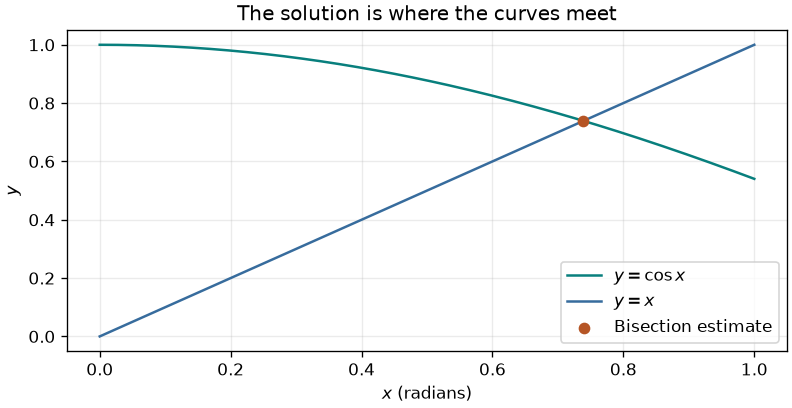

In [6]:
h = lambda t: cos(t) - t

root_c, history_c = bisect(h, 0, 1, tolerance=1e-9)
print(f"x ≈ {root_c:.10f}    |cos(x) - x| = {abs(h(root_c)):.2e}")

t = np.linspace(0, 1, 250)
fig, ax = plt.subplots(figsize=(6.6, 3.4), layout="constrained")
ax.plot(t, np.cos(t), label="$y=\\cos x$", color="#087F7D")
ax.plot(t, t, label="$y=x$", color="#376C9D")
ax.scatter(root_c, root_c, color="#B55525", zorder=3, label="Bisection estimate")
ax.set(xlabel="$x$ (radians)", ylabel="$y$", title="The solution is where the curves meet")
ax.grid()
ax.legend()
plt.show()

## 4. Approximate a definite integral with trapezoids

Use the same function $g(x)=x^2-2$ to estimate $\int_2^3 (x^2-2)\,dx$. On $[2,3]$ the curve lies above the horizontal axis, so the integral equals the area beneath it.

Split the interval into $n$ pieces. On each piece of width $\Delta x$, replace the curve by the straight line joining its two endpoint heights. The trapezoid's area is $\Delta x$ times the average of the two heights.

$$
\Delta x=\frac{b-a}{n},
\qquad
T_n=\sum_{i=0}^{n-1}\Delta x\,\frac{g(x_i)+g(x_{i+1})}{2}.
$$

Here $n$ is the number of trapezoids, so we need $n+1$ sample points. SymPy gives the exact integral $13/3$. **Predict.** Will the straight top edges lie above or below the curve?

Exact area from SymPy: 13/3
Pieces    Estimate     Absolute error
     4     4.343750         0.010417
     8     4.335938         0.002604
    16     4.333984         0.000651
    32     4.333496         0.000163


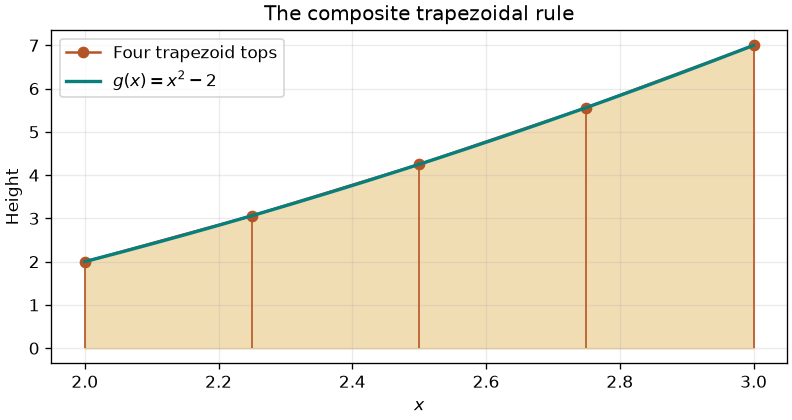

In [7]:
def trapezoid(function, a, b, n):
    grid = np.linspace(a, b, n + 1)
    heights = function(grid)
    width = (b - a) / n
    return np.sum(width * (heights[:-1] + heights[1:]) / 2)


exact_area = sp.integrate(g(x), (x, 2, 3))
print("Exact area from SymPy:", exact_area)
print("Pieces    Estimate     Absolute error")
for n in (4, 8, 16, 32):
    area = trapezoid(g, 2, 3, n)
    print(f"{n:6d}   {area:10.6f}   {abs(area - float(exact_area)):14.6f}")

grid = np.linspace(2, 3, 5)
curve_x = np.linspace(2, 3, 250)
fig, ax = plt.subplots(figsize=(6.6, 3.5), layout="constrained")
ax.fill_between(grid, g(grid), color="#EACB8C", alpha=0.65)
ax.plot(grid, g(grid), color="#B55525", marker="o", label="Four trapezoid tops")
ax.vlines(grid, 0, g(grid), color="#B55525", linewidth=1)
ax.plot(curve_x, g(curve_x), color="#087F7D", linewidth=2, label="$g(x)=x^2-2$")
ax.set(xlabel="$x$", ylabel="Height", title="The composite trapezoidal rule")
ax.grid()
ax.legend()
plt.show()

## Your turn

1. **Find another root.** Use $x^2-2$ on $[-2,-1]$. Explain why this bracket works and compare your estimate with the negative exact root from SymPy.
2. **Test the stopping rules.** Set a tight tolerance and **max_steps=3** for $\cos x-x$ on $[0,1]$. Explain the result. Then choose a step limit that lets the method finish.
3. **Integrate on a new interval.** Estimate $\int_2^4 (x^2-2)\,dx$ using 4, 8, and 16 trapezoids. Verify against SymPy. What happens to the absolute error when the number of trapezoids doubles?